In [1]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt

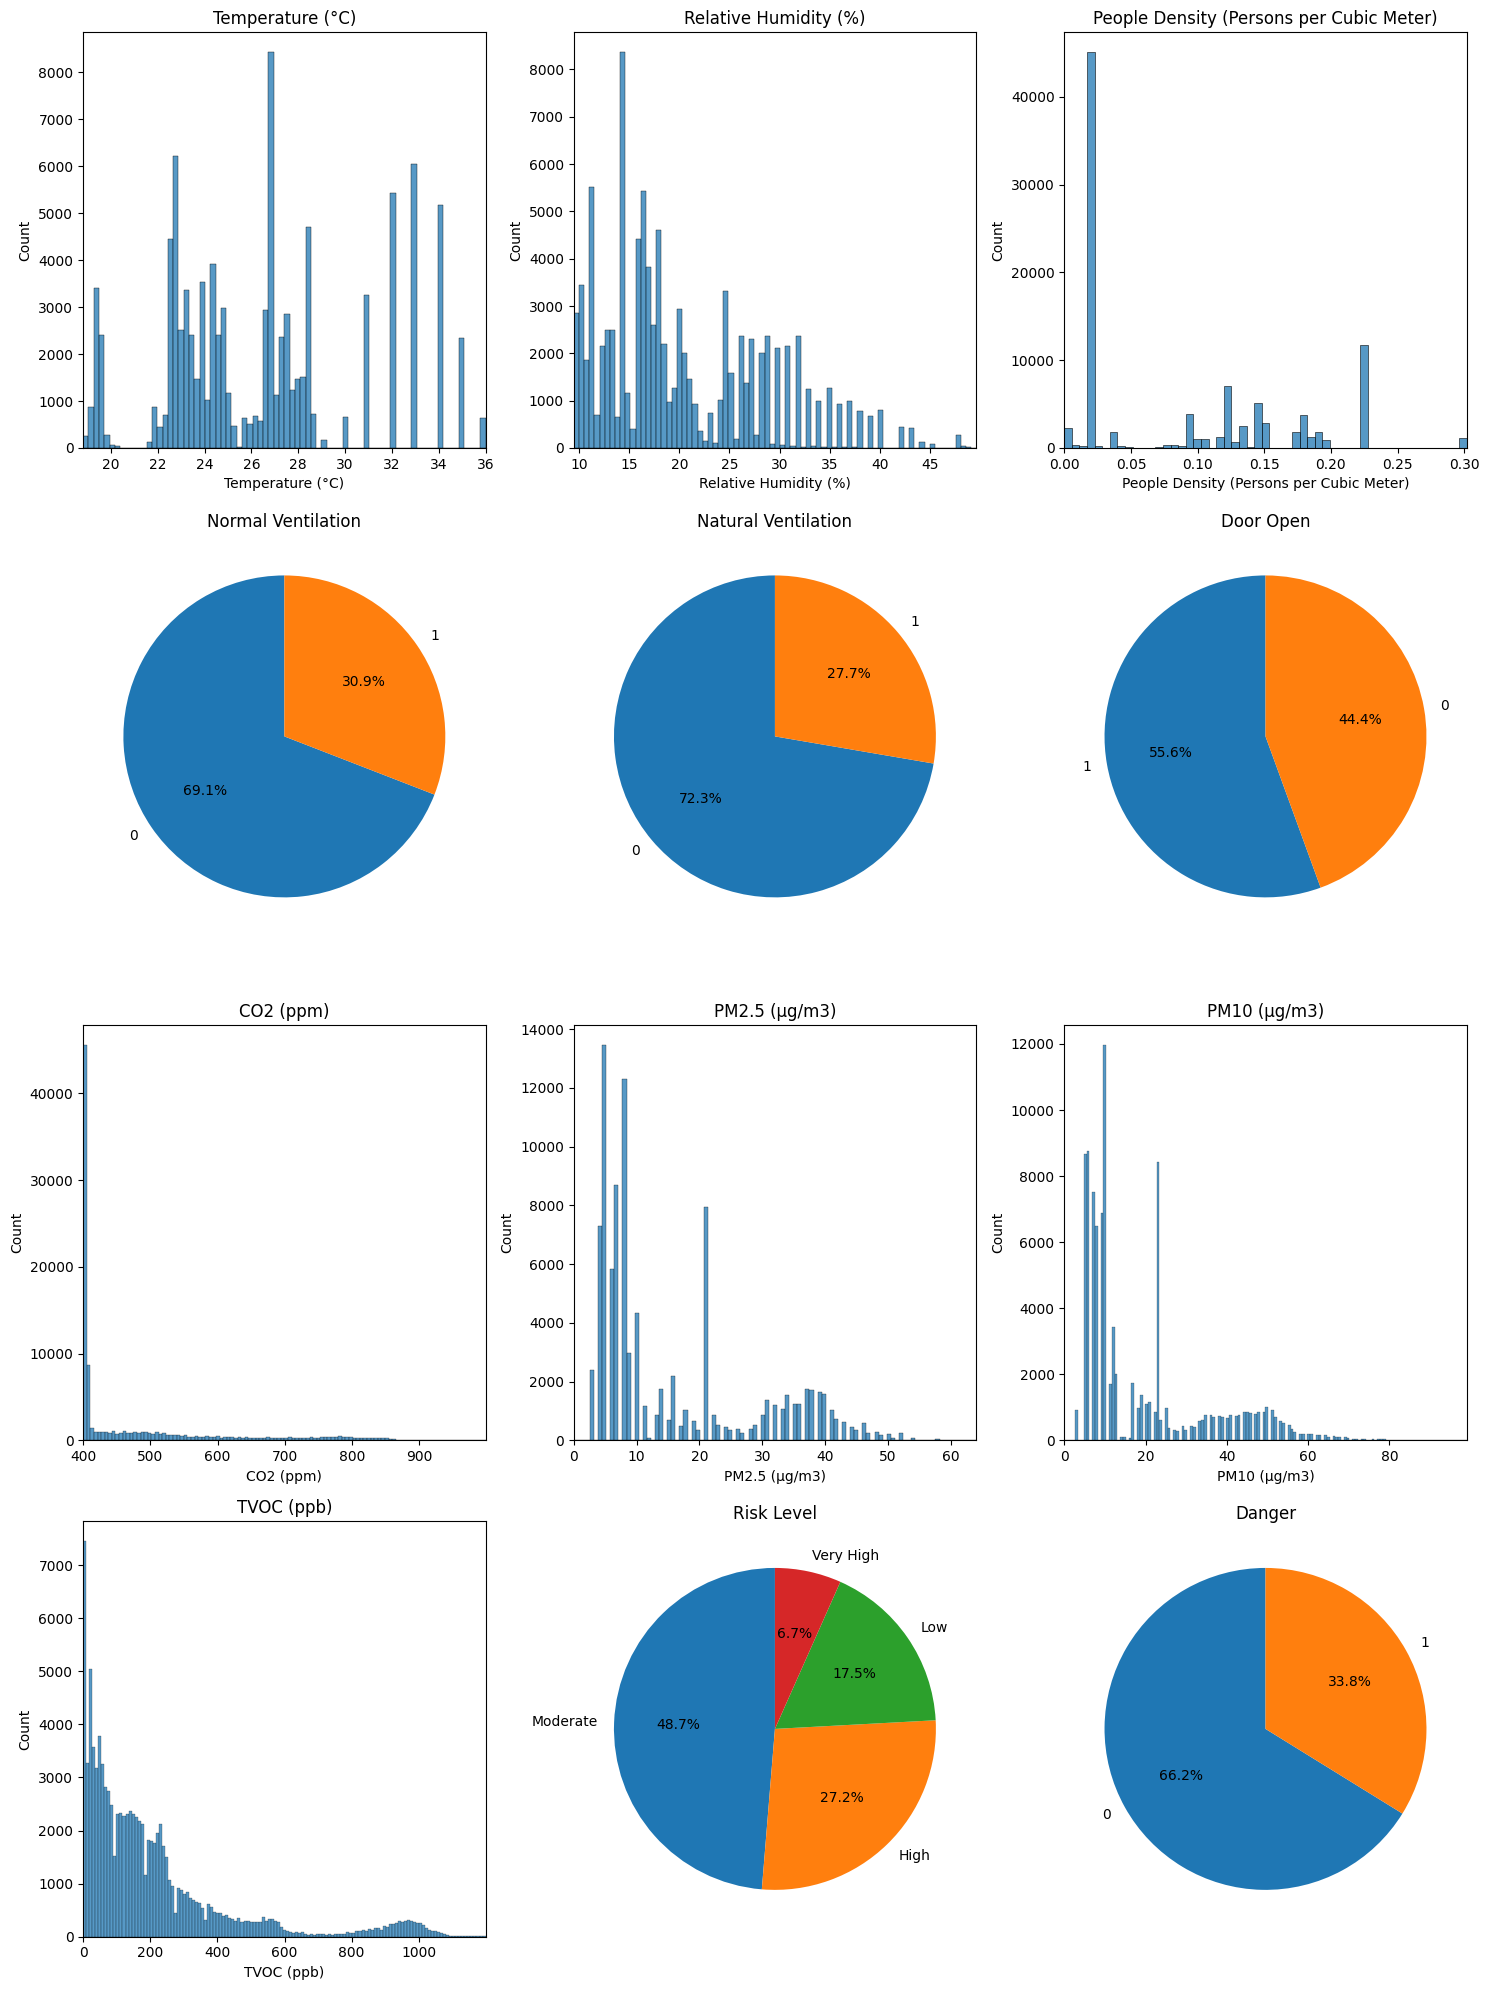

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv('dataset_nuevo_corregido.csv')

df = df[df["Humidity"] < 50]  
df = df[df["Temperature"] < 50]   
df = df[df["PM2.5"] < 100]   
df = df[df["PM10"] < 100]   
df = df[df["CO2"] < 1000]   
df = df[df["TVOC"] < 1200]   

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 20)) 
plt.subplots_adjust(hspace=0.5, wspace=0.3)

def get_bins(series):
    return np.histogram_bin_edges(series.dropna(), bins='auto')

def set_histogram(ax, series, xlabel):
    bins = get_bins(series)
    sns.histplot(x=series, ax=ax, kde=False, bins=bins)
    ax.set_xlabel(xlabel)
    ax.set_title(xlabel)
    ax.set_xlim(series.min(), series.max())

set_histogram(axes[0, 0], df["Temperature"], "Temperature (°C)")
set_histogram(axes[0, 1], df["Humidity"], "Relative Humidity (%)")
set_histogram(axes[0, 2], df["People density"], "People Density (Persons per Cubic Meter)")

counts = df["Normal ventilation"].value_counts() 
axes[1, 0].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90) 
axes[1, 0].set_title("Normal Ventilation")

counts = df["Natural ventilation"].value_counts() 
axes[1, 1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90) 
axes[1, 1].set_title("Natural Ventilation")

counts = df["Door open"].value_counts() 
axes[1, 2].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90) 
axes[1, 2].set_title("Door Open")

set_histogram(axes[2, 0], df["CO2"], "CO2 (ppm)")
set_histogram(axes[2, 1], df["PM2.5"], "PM2.5 (µg/m3)")
set_histogram(axes[2, 2], df["PM10"], "PM10 (µg/m3)")

set_histogram(axes[3, 0], df["TVOC"], "TVOC (ppb)")

counts = df["Risk_Label"].value_counts() 
axes[3, 1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90) 
axes[3, 1].set_title("Risk Level")

counts = df["Risk"].value_counts() 
axes[3, 2].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90) 
axes[3, 2].set_title("Danger")

plt.tight_layout() 
plt.show()


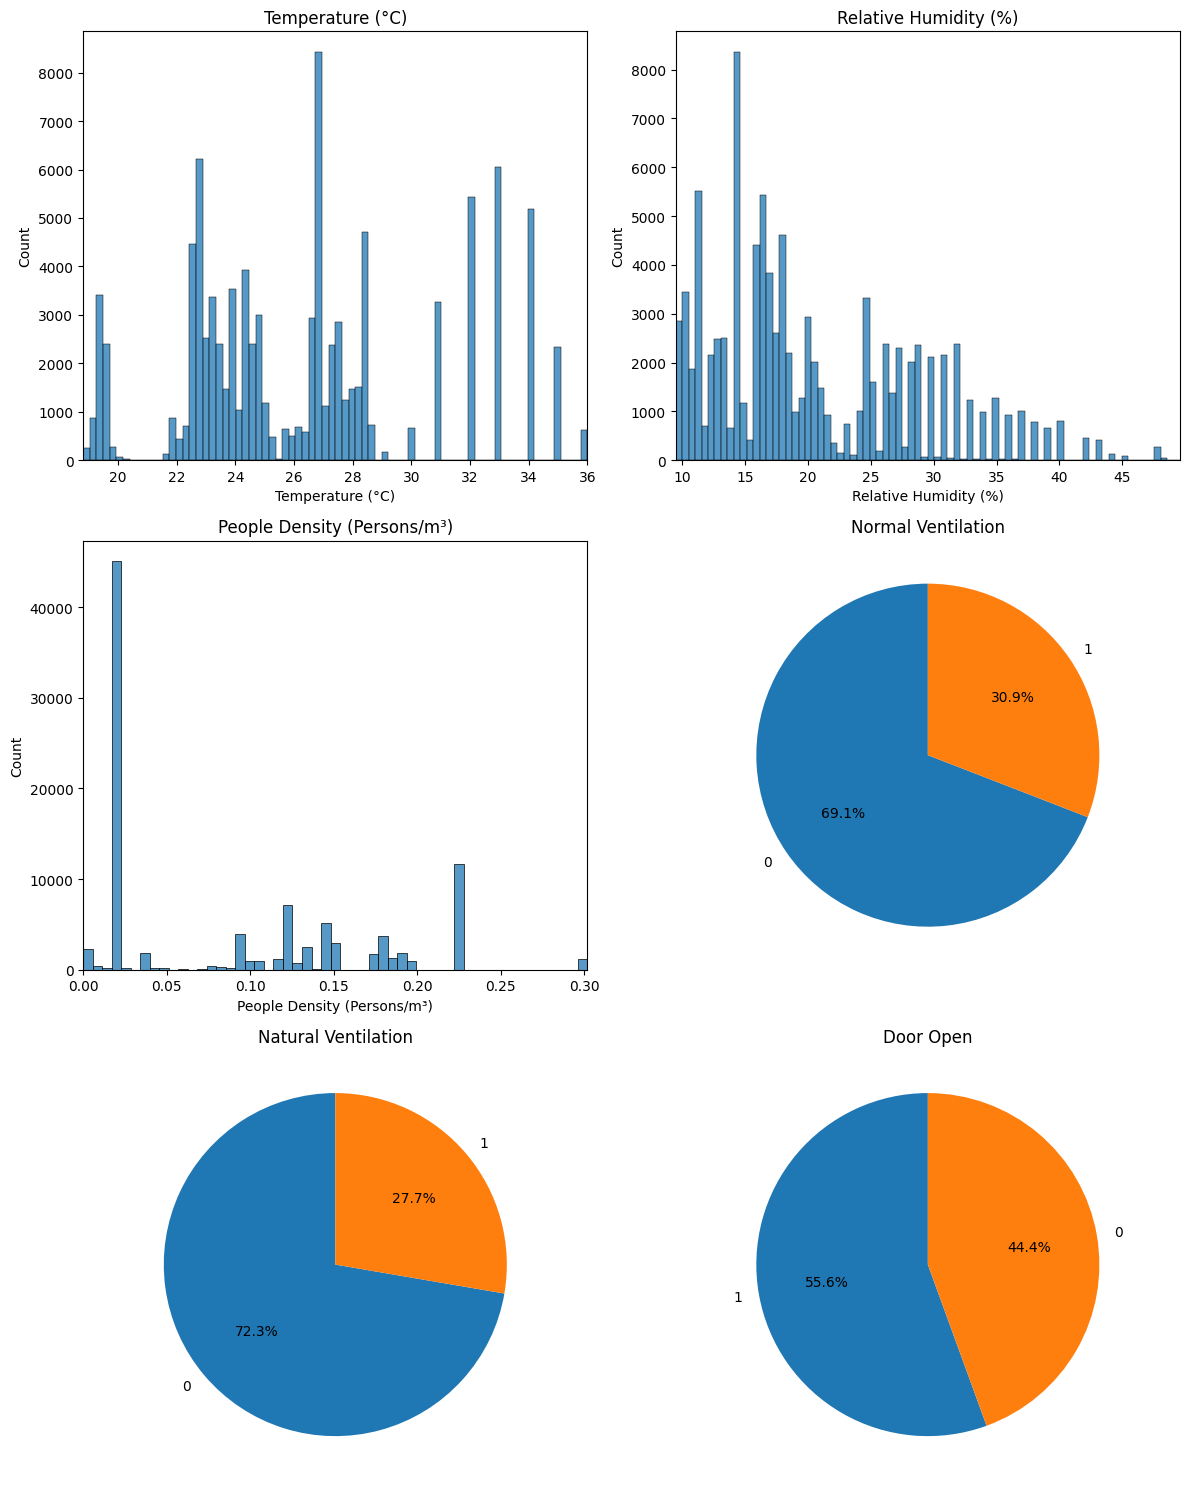

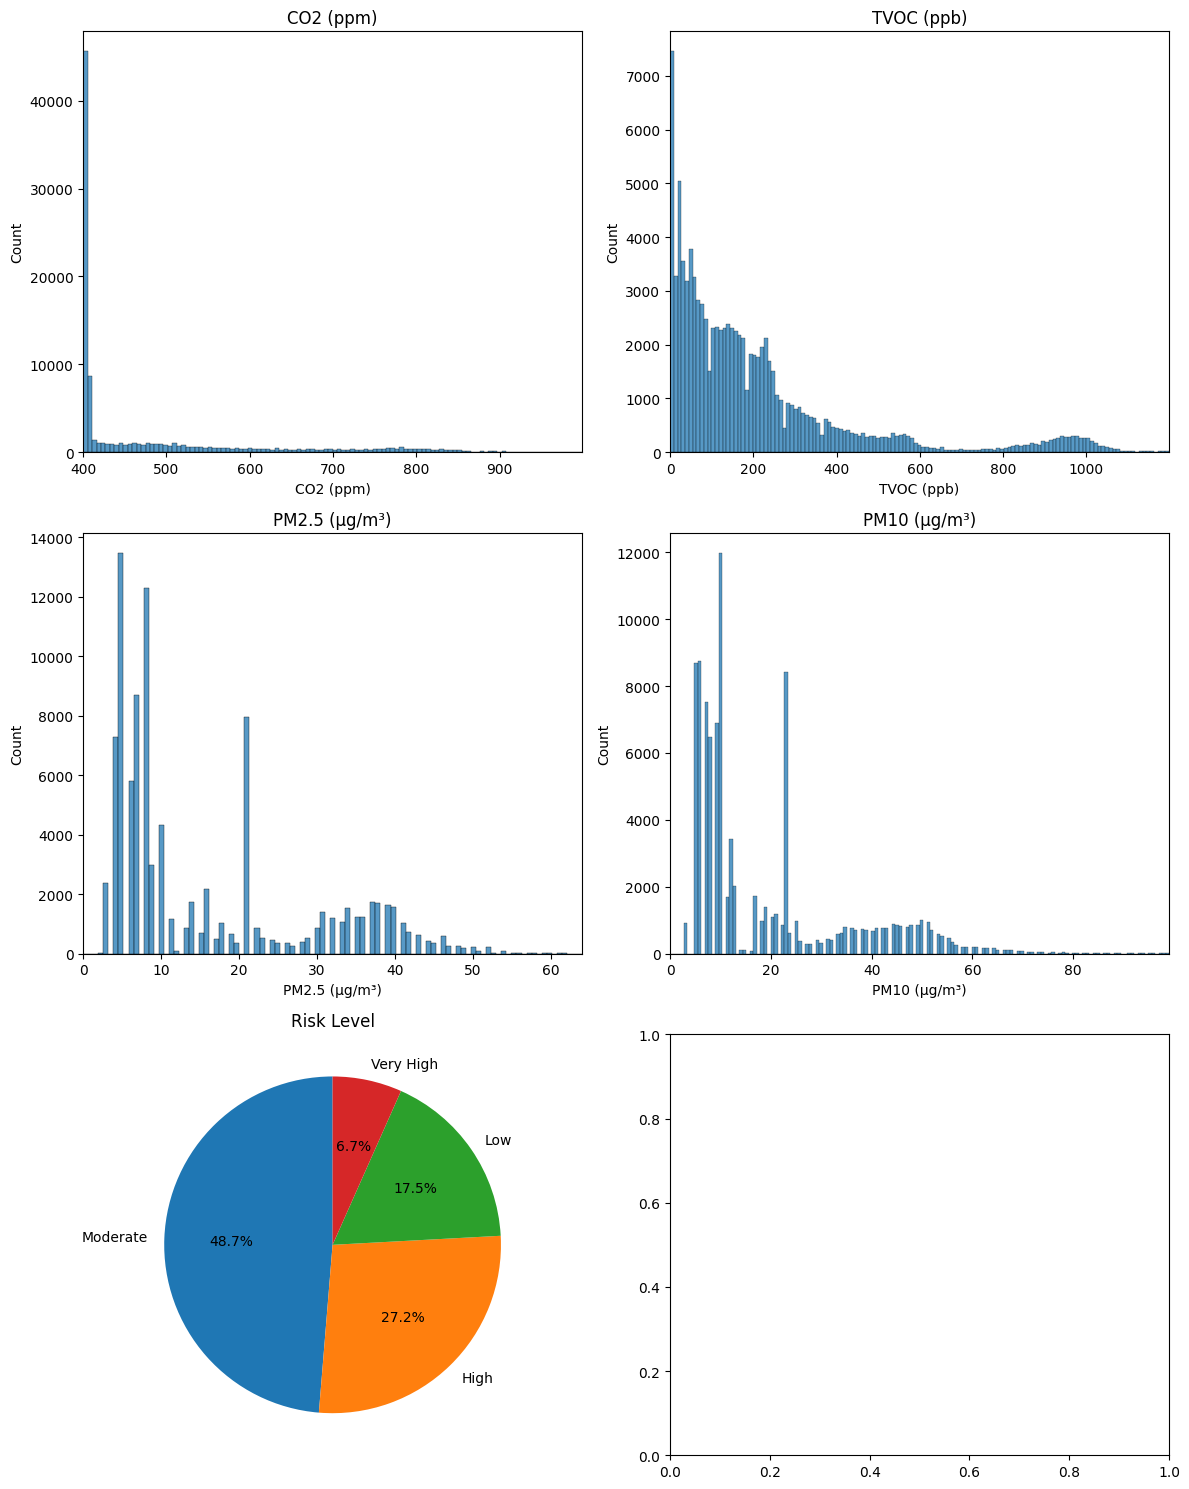

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load dataset
df = pd.read_csv('dataset_nuevo_corregido.csv')

# Filter to clean outliers
df = df[df["Humidity"] < 50]
df = df[df["Temperature"] < 50]
df = df[df["PM2.5"] < 100]
df = df[df["PM10"] < 100]
df = df[df["CO2"] < 1000]
df = df[df["TVOC"] < 1200]

# Define utility functions
def get_bins(series):
    return np.histogram_bin_edges(series.dropna(), bins='auto')

def set_histogram(ax, series, xlabel):
    bins = get_bins(series)
    sns.histplot(x=series, ax=ax, kde=False, bins=bins)
    ax.set_xlabel(xlabel)
    ax.set_title(xlabel)
    ax.set_xlim(series.min(), series.max())

def set_pie(ax, series, title):
    counts = series.value_counts()
    ax.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90)
    ax.set_title(title)

# ----------------- FIGURE 1 -----------------
fig1, axes1 = plt.subplots(nrows=3, ncols=2, figsize=(12, 15))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# Row 1
set_histogram(axes1[0, 0], df["Temperature"], "Temperature (°C)")
set_histogram(axes1[0, 1], df["Humidity"], "Relative Humidity (%)")

# Row 2
set_histogram(axes1[1, 0], df["People density"], "People Density (Persons/m³)")
set_pie(axes1[1, 1], df["Normal ventilation"], "Normal Ventilation")

# Row 3
set_pie(axes1[2, 0], df["Natural ventilation"], "Natural Ventilation")
set_pie(axes1[2, 1], df["Door open"], "Door Open")

plt.tight_layout()
plt.show()

# ----------------- FIGURE 2 -----------------
fig2, axes2 = plt.subplots(nrows=3, ncols=2, figsize=(12, 15))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# Row 1
set_histogram(axes2[0, 0], df["CO2"], "CO2 (ppm)")
set_histogram(axes2[0, 1], df["TVOC"], "TVOC (ppb)")

# Row 2
set_histogram(axes2[1, 0], df["PM2.5"], "PM2.5 (µg/m³)")
set_histogram(axes2[1, 1], df["PM10"], "PM10 (µg/m³)")

# Row 3
set_pie(axes2[2, 0], df["Risk_Label"], "Risk Level")
#set_pie(axes2[2, 1], df["Risk"], "Danger")

plt.tight_layout()
plt.show()


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression 
import pandas as pd

# Encode target variable
label_encoder = LabelEncoder()
df['Risk_Label_Encoded'] = label_encoder.fit_transform(df['Risk_Label'])

# Define features and target
features = ['Temperature', 'Humidity', 'People density', 'CO2', 'TVOC', 'PM2.5', 'PM10']
X = df[features]
y = df['Risk_Label_Encoded']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000) 
}

# Evaluate models
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall (macro)": recall_score(y_test, y_pred, average='macro'),
        "F1 Score (macro)": f1_score(y_test, y_pred, average='macro')
    })

# Results table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='F1 Score (macro)', ascending=False)
print(results_df)


                 Model  Accuracy  Recall (macro)  F1 Score (macro)
0  Logistic Regression  0.921142        0.933076          0.934125


c:\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
